# Audio analysis toolkits

#0 Imports

قبل از شروع کار مطمئن شوید که می‌توانید همه‌ی کتابخانه‌های زیر را فراخوانی کنید. برای اجرای بخش‌های مختلف این دفتر، به این کتابخانه‌ها نیاز خواهید داشت.

In [ ]:
!pip install "openai~=1.14.1" "transformers~=4.39.1" "librosa~=0.10.1" "matplotlib~=3.7.1" pysptk

In [ ]:
import pysptk
from pysptk.synthesis import MLSADF, Synthesizer
import librosa
import librosa.display
import librosa.effects
import librosa.util

import numpy as np
import matplotlib.pyplot as plt

# used to play audio files
import IPython.display as ipd
from base64 import b64decode


# 1 Data preparation

## 1.1 Data loading

In [ ]:
# download dataset from public GDrive
!wget -O hvb_sampledata.zip https://drive.usercontent.google.com/download?id=1tFaTu7LWuCxn3DkAyudGGyv6eilVO5pC
#https://drive.google.com/file/d/1tFaTu7LWuCxn3DkAyudGGyv6eilVO5pC

In [ ]:
!ls
!unzip -o hvb_sampledata.zip

In [ ]:
ls sample

In [ ]:
ls sample/agent

In [ ]:
ls sample/caller

## 1.2 Playing audio files

In [ ]:
# agent side of the conversation
ipd.Audio('./sample/agent/0002f70f7386445b.wav')

In [ ]:
# caller side of the conversation
ipd.Audio('./sample/caller/0002f70f7386445b.wav')

## 1.3 Loading audio into an array

In [ ]:
# sr represents a "sample rate"
wav_agent, sr_agent = librosa.load('./sample/agent/0002f70f7386445b.wav')
wav_caller, sr_caller = librosa.load('./sample/caller/0002f70f7386445b.wav')

## 1.4 Combine both conversation sides into a single array

In [ ]:
merged_wav = None # TODO: define this variable
sr_merged = sr_agent

#############################
#### YOUR CODE GOES HERE ####

# pad the shorter signal with zeros so both are the same length, then sum them
max_len = max(len(wav_agent), len(wav_caller))
wav_agent_padded = librosa.util.fix_length(wav_agent, size=max_len)
wav_caller_padded = librosa.util.fix_length(wav_caller, size=max_len)
merged_wav = wav_agent_padded + wav_caller_padded

#############################

In [ ]:
ipd.Audio(merged_wav, rate=sr_merged)

# 2 Visualizing audio using time-frequency spectrograms

In [ ]:
# helper function to plot a mel spectrogram
# arguments: (wave array, sampling rate, number of mel bins, max frequency of mel scale)
def plot_melspectrogram(wav, sr, annotations=None, n_mels=256, fmax=4096,
                        fig=None, ax=None, show_legend=True):

    if ax == None:
      fig, ax = plt.subplots(1,1,figsize=(20,5))
    M = librosa.feature.melspectrogram(y=wav, sr=sr, n_mels=n_mels, fmax=fmax, n_fft=2048)
    M_db = librosa.power_to_db(M, ref=np.max)
    img = librosa.display.specshow(M_db, y_axis='mel', x_axis='time', ax=ax, fmax=fmax)
    if show_legend:
      ax.set(title='Mel spectrogram display')
      fig.colorbar(img, ax=ax, format="%+2.f dB")

    # iterate over list of text annotations and draw them
    if annotations is not None:
        for x,y,text in annotations:
            ax.annotate(
            text,
            xy=(x,y), xycoords='data',
            xytext=(10, -50), textcoords='offset pixels',
            horizontalalignment='right',
            color='white',
            fontsize=20,
            verticalalignment='bottom',
            arrowprops=dict(
                arrowstyle= '-|>',
                 color='white',
                 lw=1,
                 ls='-')
            )

اکنون می‌توانیم از تابع کمکی برای تصویرسازی طیف‌نگاری مل از فایل صوتی ترکیبی که ایجاد کرده‌اید استفاده کنیم

In [ ]:
plot_melspectrogram(merged_wav, sr_agent, annotations=None, n_mels=256, fmax=sr_agent/2)

توجه داشته باشید که هیچ انرژی بالاتر از 4 کیلوهرتز وجود ندارد. مجموعه داده با استفاده از گفتار تلفنی که دارای نرخ نمونه برداری 8 کیلوهرتز است، جمع آوری شده است. بنابراین بالاترین فرکانس معنی دار در این ضبط‌ها 4 کیلوهرتز می‌باشد. برای راحتی کار، آرگومان‌های تابع تصویرسازی برای نمایش صدا، برای پیش‌فرض طبق بیشینه‌ی انرژی گفتار تلفنی تنظیم گردیده‌اند.

In [ ]:
# we can adjust the keyword arguments
fmax_dataset = 4096
plot_melspectrogram(merged_wav, sr_agent, annotations=None, n_mels=256, fmax=fmax_dataset)
plot_melspectrogram(merged_wav, sr_agent)

## 2.1 Silence removal

In [ ]:
recon_agent = None # TODO: create a NumPy array with silences removed

#############################
#### YOUR CODE GOES HERE ####

# split the signal on silence, then glue the remaining (speech) chunks back together
intervals = librosa.effects.split(wav_agent, top_db=30)
recon_agent = np.concatenate([wav_agent[start:end] for start, end in intervals])

#############################

In [ ]:
# listen to your audio file
ipd.Audio(recon_agent, rate=sr_agent)

In [ ]:
# This should now have minimal gaps between utterances
# (leaving some small silences is okay)
plot_melspectrogram(recon_agent, sr_agent)

## 2.2 Segment a single utterance

In [ ]:
audio_signal = None # TODO: represent as a NumPy array

#############################
#### YOUR CODE GOES HERE ####

# Slicing out just the greeting sentence from the cleaned agent audio:
# "This is Harper Valley National Bank. My name is Elizabeth. How can I help you today?"
start_sec, end_sec = 0.5, 4.2
audio_signal = recon_agent[int(start_sec * sr_agent):int(end_sec * sr_agent)]

#############################

In [ ]:
# listen to your audio file
ipd.Audio(audio_signal, rate=sr_agent)

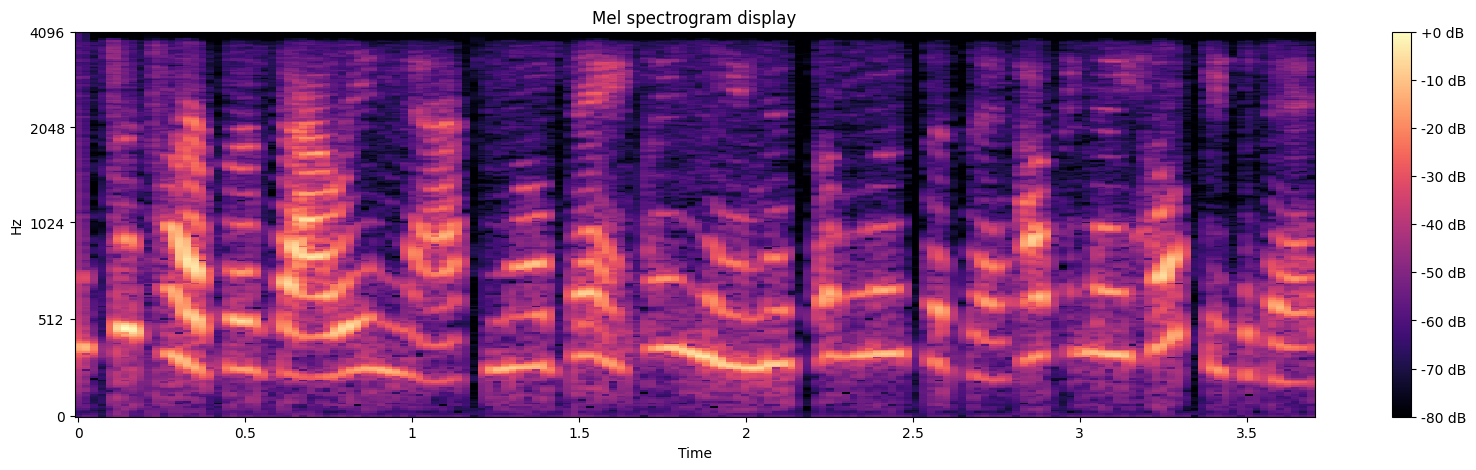

In [ ]:
plot_melspectrogram(audio_signal, sr_agent)

## 2.3 Label words in the spectrogram

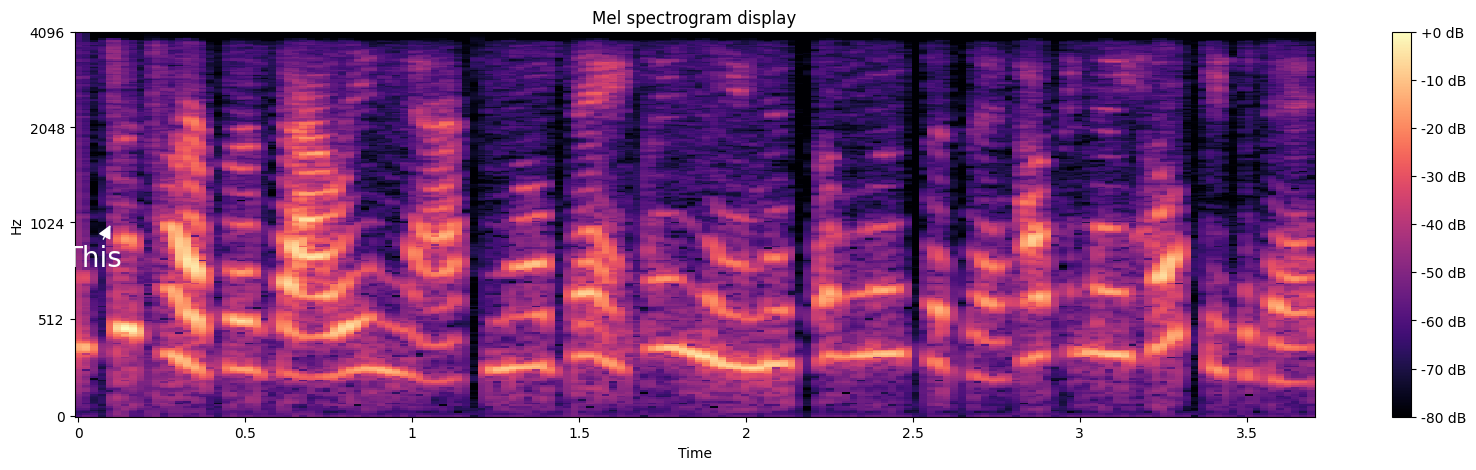

In [ ]:
utt_words = [(0.1, 1024, 'This'),]
plot_melspectrogram(audio_signal, sr_agent, annotations=utt_words)

In [ ]:
# TODO: Position the remaining words correctly using the same format:
#  (time (s), frequency(Hz), annotation(string))
utt_words = [(0.1, 1024, 'This'),]
#############################
#### YOUR CODE GOES HERE ####

utt_words = [
    (0.10, 1024, 'This'),
    (0.31, 2600, 'is'),
    (0.50, 1400, 'Harper'),
    (0.77, 3200, 'Valley'),
    (0.98,  700, 'National'),
    (1.16, 2200, 'Bank.'),
    (1.32, 3600, 'My'),
    (1.55, 1000, 'name'),
    (1.78, 2800, 'is'),
    (2.3, 1600, 'Elizabeth.'),
    (2.58, 3400, 'How'),
    (2.71,  600, 'can'),
    (2.85, 2400, 'I'),
    (3.02, 1200, 'help'),
    (3.28, 3000, 'you'),
    (3.52, 1800, 'today?')
]

#############################

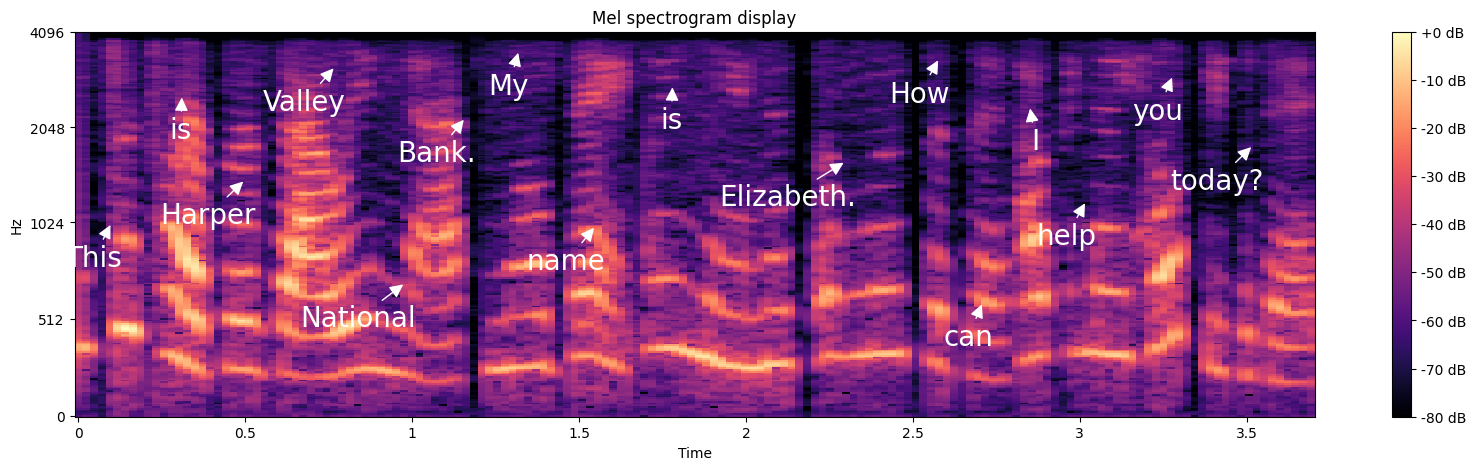

In [ ]:
plot_melspectrogram(audio_signal, sr_agent, annotations=utt_words)

## 2.4 Visually estimate mean F_0

 بخش 2.4 فاقد پیاده‌سازیست و تنها در فایل گزارش به سوال آن پاسخ دهید.

# 3 Visualizing alternative audio representations

تابع کمکی جهت رسم نمودار سری زمانی موج خام

In [ ]:
def show_waveplot(audio_signal,sr,annotations=None):
    fig, ax = plt.subplots(1,1,figsize=(20,5))
    # librosa.display.waveplot(audio_signal, sr=sr)
    librosa.display.waveshow(audio_signal, sr=sr)
    # iterate over list of text annotations and draw them
    if annotations is not None:
        for x,y,text in annotations:

            ax.annotate(
            text,
            xy=(x,y), xycoords='data',
            xytext=(10, -50), textcoords='offset pixels',
            horizontalalignment='right',
            color='black',
            fontsize=20,
            verticalalignment='bottom',
            arrowprops=dict(
                arrowstyle= '-|>',
                 color='black',
                 lw=1,
                 ls='-')
            )

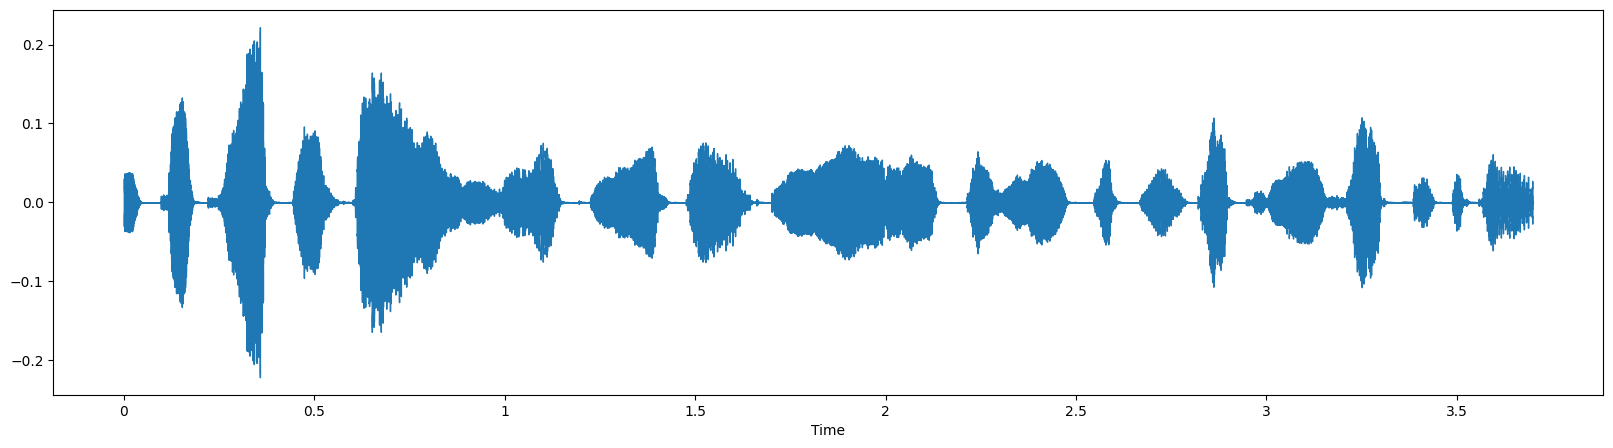

In [ ]:
show_waveplot(audio_signal,sr_agent)

## 3.1 Label words in the time domain plot

In [ ]:
#  (time (s), amplitude, annotation(string))
utt_words = [(0.1, 0, 'This'),]
#############################
#### YOUR CODE GOES HERE ####

utt_words = [
    (0.10,  0.10, 'This'),
    (0.31,  0.00, 'is'),
    (0.50, 0.1, 'Harper'),
    (0.77,  0.00, 'Valley'),
    (0.98, 0.1, 'National'),
    (1.16,  0.0, 'Bank.'),
    (1.32, 0.1, 'My'),
    (1.55,  0.0, 'name'),
    (1.78, 0.1, 'is'),
    (2.3,  0.0, 'Elizabeth.'),
    (2.58, 0.1, 'How'),
    (2.71,  0.0, 'can'),
    (2.85, 0.1, 'I'),
    (3.02,  0.0, 'help'),
    (3.28, 0.1, 'you'),
    (3.52,  0.0, 'today?')
]

#############################

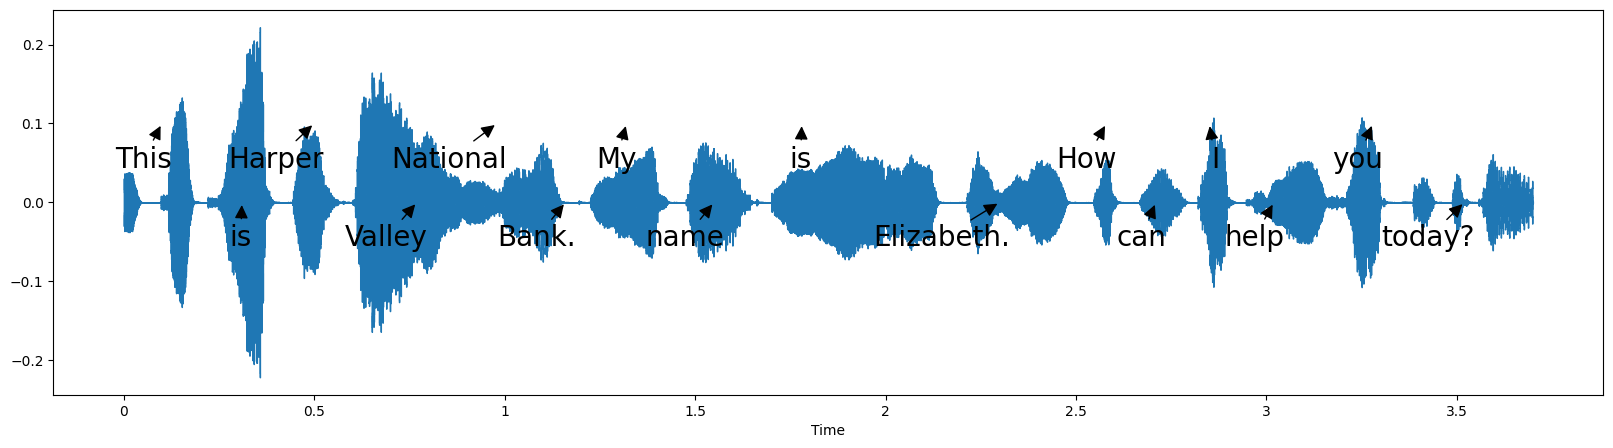

In [ ]:
show_waveplot(audio_signal,sr_agent,utt_words)

## 3.2 Computing Mel frequency cepstral coefficient (MFCC) features

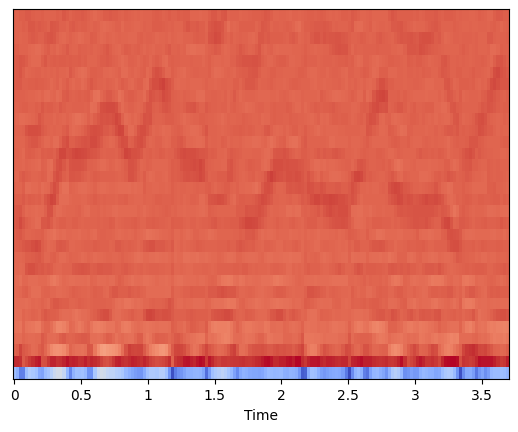

In [ ]:
mfcc_feats = None #TODO fill this in
# start with these Mel spectrograms so MFCC computes only the final transform
# alternatively you can compute MFCCs from the orignal waveform but ensure you pass
#   arguments to .mfcc() to match our Mel Spectrogram processing above
mel_feats = librosa.feature.melspectrogram(y=audio_signal, sr=sr_agent,
                                           n_mels=256, fmax=4096, n_fft=2048)
log_mel_feats = librosa.power_to_db(mel_feats, ref=np.max)

#############################
#### YOUR CODE GOES HERE ####

# compute 32 MFCCs (hop_length=512 matches the default hop used above) from the mel spectrogram
mfcc_feats = librosa.feature.mfcc(S=log_mel_feats, n_mfcc=32)

#############################

# This will display your MFCCs. We do not expect this to be a meaningful visual
# We only use this plot to check your MFCC values while grading
librosa.display.specshow(mfcc_feats, x_axis='time')

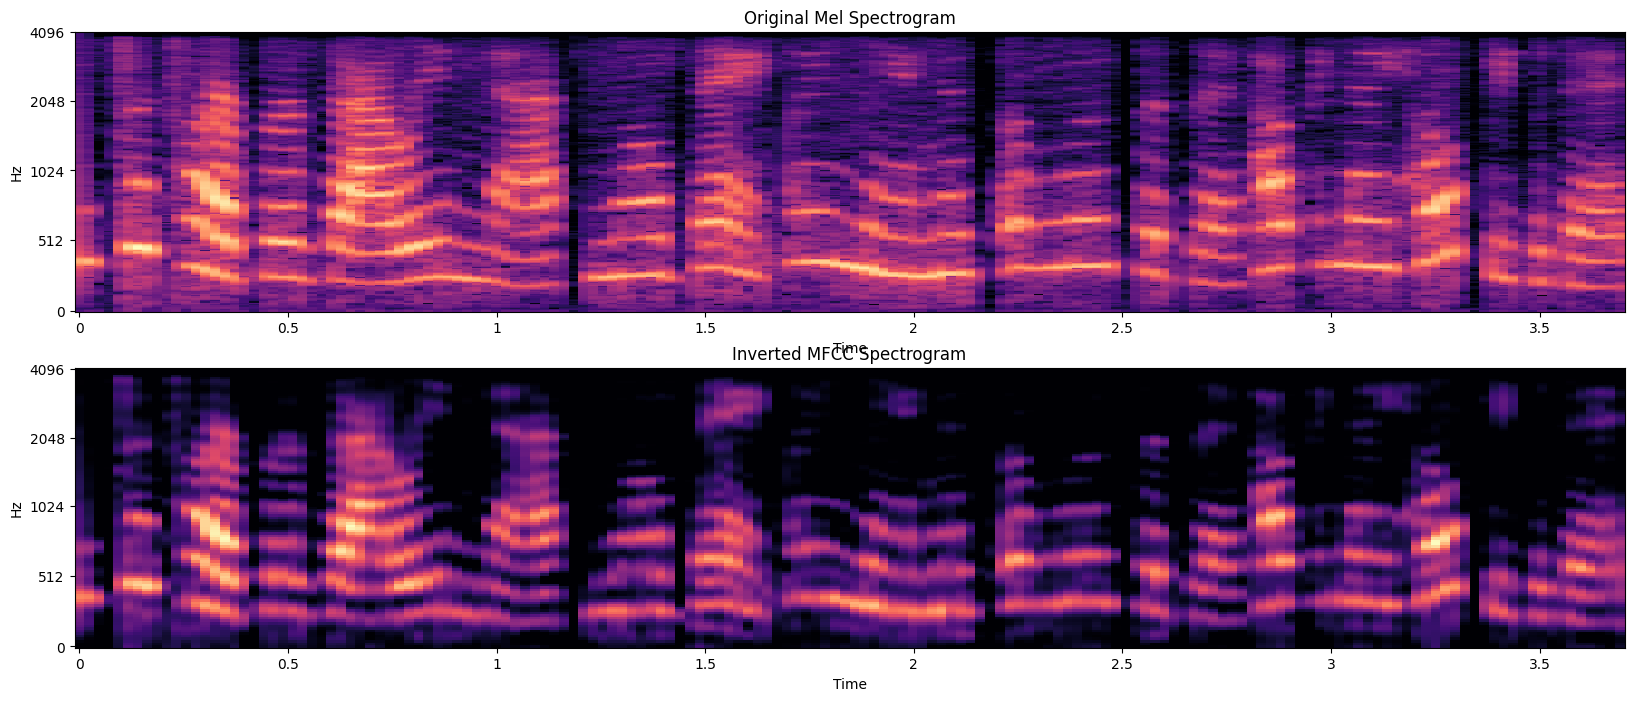

In [ ]:
fig, ax = plt.subplots(2,1,figsize=(20,8))
librosa.display.specshow(log_mel_feats,
                         x_axis='time', y_axis='mel', fmax=4096, ax=ax[0])
ax[0].set_title('Original Mel Spectrogram')

# this inverts the MFCC transform, takes the log of the Mel spectrum, and plots
librosa.display.specshow(librosa.power_to_db(librosa.feature.inverse.mfcc_to_mel(mfcc_feats),
                                             ref=np.max),
                         x_axis='time', y_axis='mel', fmax=4096, ax=ax[1])
ax[1].set_title('Inverted MFCC Spectrogram')
plt.show()


# 4 Pitch estimation and warping

In [ ]:
# our calls are loaded with a sampling rate of 22kHz.
# 1024 hop size means we compute a pitch estimate approxiately every .046 seconds
pitch_hop = 1024
voicing_threshold = 0.3
f0_swipe = pysptk.swipe(audio_signal, fs=sr_agent, hopsize=pitch_hop,
                        min=60, max=512, otype="f0", threshold=voicing_threshold)


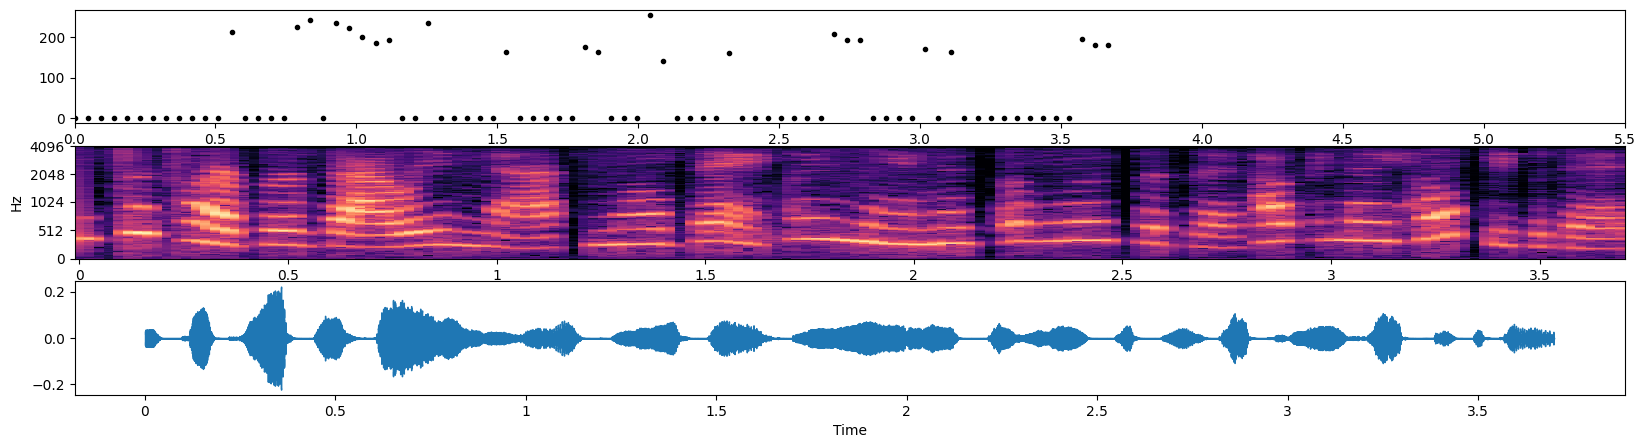

In [ ]:
time_labels = (pitch_hop / sr_agent) * np.arange(len(f0_swipe))

fig, ax = plt.subplots(3,1,figsize=(20,5))
ax[0].plot(time_labels, f0_swipe, 'k.')
ax[0].set_xlim([0, time_labels[-1]])
ax[0].set_xticks(np.arange(6.0, step=0.5))

plot_melspectrogram(audio_signal, sr_agent, annotations=None, n_mels=256,
                    fmax=4096, fig=fig, ax=ax[1], show_legend=False)
librosa.display.waveshow(audio_signal, sr=sr_agent, ax=ax[2])

## 4.1 Try pitch extraction variations to improve

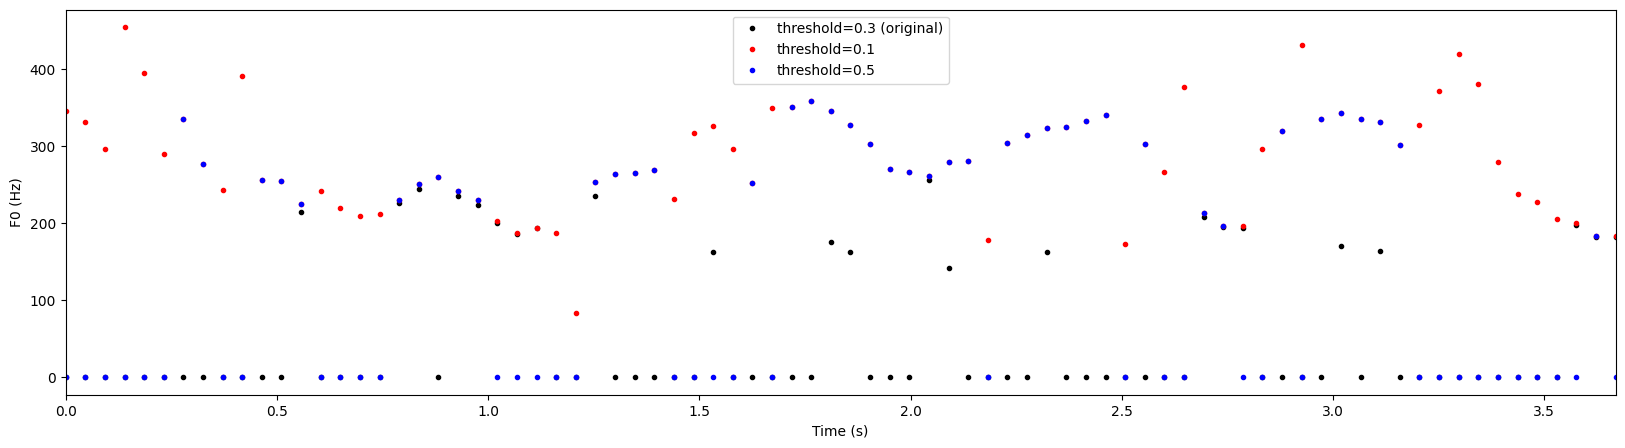

In [ ]:
#############################
#### YOUR CODE GOES HERE ####

# try two alternative voicing_threshold settings for SWIPE
f0_swipe_low_thresh = pysptk.swipe(audio_signal, fs=sr_agent, hopsize=pitch_hop,
                                   min=60, max=512, otype="f0", threshold=0.1)
f0_swipe_high_thresh = pysptk.swipe(audio_signal, fs=sr_agent, hopsize=pitch_hop,
                                    min=60, max=512, otype="f0", threshold=0.5)

plt.figure(figsize=(20, 5))
plt.plot(time_labels, f0_swipe, 'k.', label='threshold=0.3 (original)')
plt.plot(time_labels, f0_swipe_low_thresh, 'r.', label='threshold=0.1')
plt.plot(time_labels, f0_swipe_high_thresh, 'b.', label='threshold=0.5')
plt.xlim([0, time_labels[-1]])
plt.xlabel('Time (s)')
plt.ylabel('F0 (Hz)')
plt.legend()
plt.show()

#############################

## 4.2 Pitch warping

در این بخش ابتدا مجددا فایل صدا با مقدار زیر و بمی اصلی را گوش می‌دهید و سپس میزان زیر و بمی را تغییر داده و صداهای تولید شده‌ی جدید را نیز می‌شنوید.

In [ ]:
# recall our original snippet
ipd.Audio(audio_signal, rate=sr_agent)

In [ ]:
# shift up by four half steps
audio_u4hs = librosa.effects.pitch_shift(audio_signal, sr=sr_agent, n_steps=4)
ipd.Audio(audio_u4hs, rate=sr_agent)

In [ ]:
# shift down by six half steps
audio_d6hs = librosa.effects.pitch_shift(audio_signal, sr=sr_agent, n_steps=-6)
ipd.Audio(audio_d6hs, rate=sr_agent)

### 4.2.1 Extract and plot F0 for pitch-shifted examples

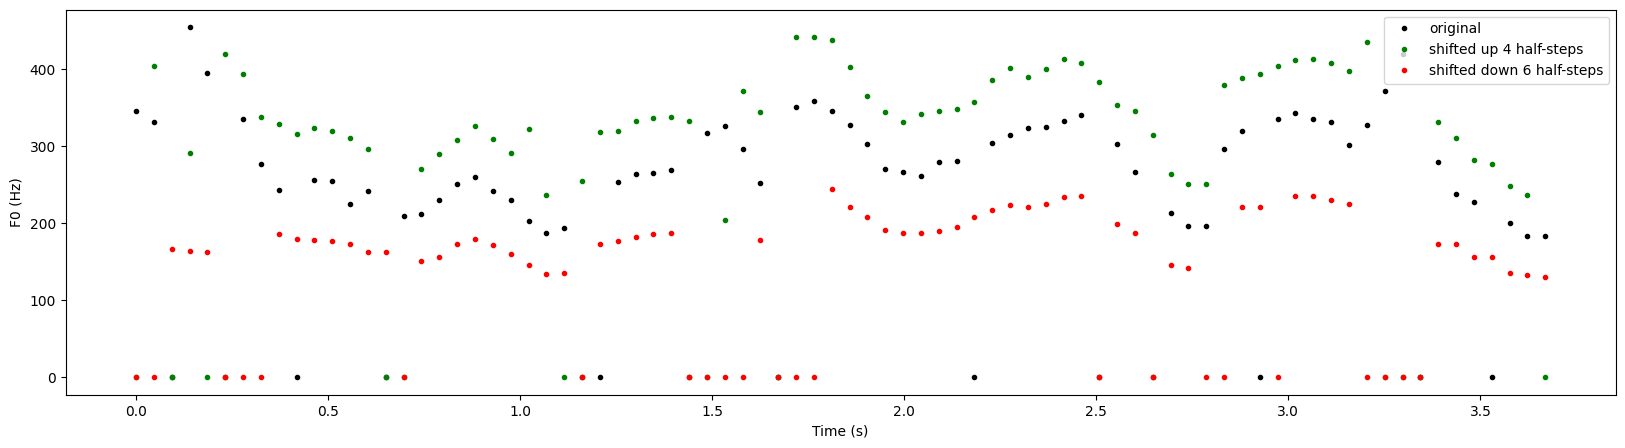

In [ ]:
#############################
#### YOUR CODE GOES HERE ####

f0_original = pysptk.swipe(audio_signal, fs=sr_agent, hopsize=pitch_hop,
                           min=60, max=512, otype="f0", threshold=voicing_threshold)
f0_up = pysptk.swipe(audio_u4hs, fs=sr_agent, hopsize=pitch_hop,
                     min=60, max=512, otype="f0", threshold=voicing_threshold)
f0_down = pysptk.swipe(audio_d6hs, fs=sr_agent, hopsize=pitch_hop,
                       min=60, max=512, otype="f0", threshold=voicing_threshold)

time_labels_shift = (pitch_hop / sr_agent) * np.arange(len(f0_original))

plt.figure(figsize=(20, 5))
plt.plot(time_labels_shift, f0_original, 'k.', label='original')
plt.plot(time_labels_shift, f0_up, 'g.', label='shifted up 4 half-steps')
plt.plot(time_labels_shift, f0_down, 'r.', label='shifted down 6 half-steps')
plt.xlabel('Time (s)')
plt.ylabel('F0 (Hz)')
plt.legend()
plt.show()

#############################

# 5 Synthesizing from Mel spectral envelopes

تابع کمکی زیر را اجرا نمایید. در ادامه به کمک آن صدای خود را بازسازی مجدد خواهید کرد.

In [ ]:
# arguments: (wave array, sampling rate, number of mel bins, max frequency of mel scale)
def resynth_audio(wav, sr_orig, sr_tosynth=8192):
  order = 25
  alpha = 0.41
  frame_length = 512
  hop_length = 40

  # resample audio signal to 8kHz for easier work with pysptk synth tools
  # pysptk does not set a max frequency when computing the mel cepstrum features
  # thus it's easier to resample the audio so that sample_rate = 2*max_frequency
  signal_to_synth = librosa.resample(wav, orig_sr=sr_orig, target_sr=sr_tosynth)

  # frames used in computing MFCCs in pysptk
  frames = librosa.util.frame(signal_to_synth, frame_length=frame_length,
                              hop_length=hop_length).astype(np.float64).T
  # Windowing
  frames *= pysptk.blackman(frame_length)

  mc = pysptk.mcep(frames, order, alpha, etype=1, eps=1e-8)
  logH = pysptk.mgc2sp(mc, alpha, 0.0, frame_length).real

  librosa.display.specshow(logH.T, sr=sr_tosynth, hop_length=hop_length, x_axis="time", y_axis="linear")
  plt.colorbar()
  plt.show()

  # Convert mel-cesptrum (MFCC) to MLSADF coefficients
  b = pysptk.mc2b(mc, alpha)

  # extract pitch
  pitch = pysptk.swipe(signal_to_synth.astype(np.float64), fs=sr_tosynth,
                       hopsize=hop_length, min=60, max=300, otype="pitch")
  source_excitation = pysptk.excite(pitch, hop_length)

  synthesizer = Synthesizer(MLSADF(order=order, alpha=alpha), hop_length)

  x_synthesized = synthesizer.synthesis(source_excitation, b)
  return x_synthesized

برای ضبط صدای خود، می‌توانید از تابع کمکی زیر استفاده کنید. برای این کار باید دسترسی به میکروفون را در مرورگر خود مجاز کنید و یک میکروفون داشته باشید.

In [ ]:
RECORD = """
const sleep  = time => new Promise(resolve => setTimeout(resolve, time))
const b2text = blob => new Promise(resolve => {
  const reader = new FileReader()
  reader.onloadend = e => resolve(e.srcElement.result)
  reader.readAsDataURL(blob)
})
var record = time => new Promise(async resolve => {
  stream = await navigator.mediaDevices.getUserMedia({ audio: true })
  recorder = new MediaRecorder(stream)
  chunks = []
  recorder.ondataavailable = e => chunks.push(e.data)
  recorder.start()
  await sleep(time)
  recorder.onstop = async ()=>{
    blob = new Blob(chunks)
    text = await b2text(blob)
    resolve(text)
  }
  recorder.stop()
})
"""

def record(sec=5):
  try:
    from google.colab import output
  except ImportError:
    print('No possible to import output from google.colab')
    return ''
  else:
    print('Recording')
    display(ipd.Javascript(RECORD))
    s = output.eval_js('record(%d)' % (sec*1000))
    fname = 'recorded_audio.wav'
    print('Saving to', fname)
    b = b64decode(s.split(',')[1])
    with open(fname, 'wb') as f:
      f.write(b)
    return fname

اینجا یک مثال از بازسازی مجدد گفتار آزمایشی ما است:

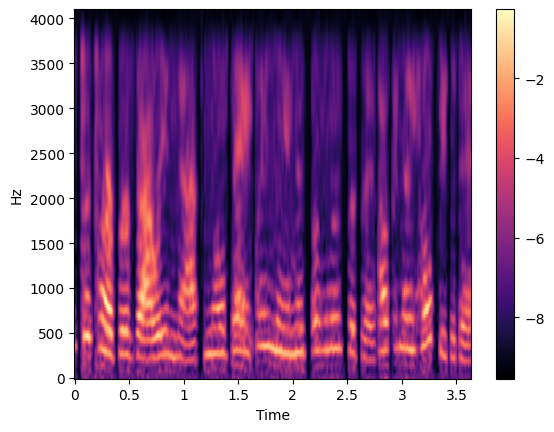

In [ ]:
synth_sr = 8192
synth_wav = resynth_audio(audio_signal, sr_agent, synth_sr)

ipd.Audio(synth_wav, rate=synth_sr)

## 5.1 Record yourself and resynthesize your utterance!

جمله‌ی گفته شده در فایل صوتی منبع را در زیر نوشته‌ایم. در 5 ثانیه جمله را بخوانید و صدای خود را ضبط نمایید.

This is Harper Valley National Bank. My name is Elizabeth. How can I help you today?

In [ ]:
# record yourself speaking!
# If this fails you can record using a system utility and upload the .wav file
record(5)

In [ ]:
# convert the file format from not actually a wav to a wav
!ffmpeg -y -i ./recorded_audio.wav out.wav

In [ ]:
from scipy.io import wavfile
import numpy as np
# Play your audio file to verify it worked
sr, dat = wavfile.read("./out.wav")
# Split out to view one channel
l_ch = dat[:, 0]

# plot the audio channel
fig, ax = plt.subplots(2,1,figsize=(20,15))
plot_melspectrogram(l_ch.astype(np.float32), sr=sr, ax=ax[0], fig=fig, n_mels=196)
librosa.display.waveshow(l_ch.astype(np.float32), sr=sr, ax=ax[1])

ipd.Audio(l_ch, rate=sr)

In [ ]:
# it's okay to see a warning about PySoundFile here.
# It's due to the saved format of the recorded wav file
wav_mine, sr_mine = librosa.load('recorded_audio.wav')

در این قسمت روی صدای ضبط شده‌ی خود بازسازی مجدد انجام می‌دهید:

In [ ]:
synth_sr = 16000
synth_wav = resynth_audio(wav_mine, sr_mine, synth_sr)

ipd.Audio(synth_wav, rate=synth_sr)

صدای اصلی تولید شده توسط خودتون و صدای بازسازی شده‌ی خودتون رو شنیدید. با توجه به مشاهدات خود به سوال مطرح شده در  فایل متن تمرین پاسخ دهید.

# 6 Generating Synthetic Voices

### 6.1 Using rime.ai Text-to-Speech model (TTS)

Let's try [rime.ai](https://rime.ai/)!!

با استفاده از مدل معرفی شده، و طبق توضیحات فایل متنی تمرین، 5 جمله تولید کنید.

 به کمک پیاده‌سازی انجام شده در این بخش، جملات ضبط شده‌ی خود را یکی یکی فراخوانی نموده، به فرمت مورد نظر تبدیل نمایید و تا در ادامه در برنامه‌ی خود از آن‌ها استفاده نمایید.

فرمت مورد نظر: .wav


In [ ]:
# At first upload the Audio Files to your google drive
# and Install Required Libraries
!pip install pydub
!apt-get install ffmpeg

In [ ]:
# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Import needed libraries
from pydub import AudioSegment
import os

در قطعه کد زیر بایستی آدرس فایل صوتی خودتان در گوگل درایو را جایگزین آدرس نمادین در خط اول کد بکنید.

file_path = " path to your audio file "

In [ ]:
# Get the uploaded file path
file_path = '/path/to/your/voice/recording/file'


# Load the audio file
audio = AudioSegment.from_file(file_path)

# Set the output file name
wav_file_name = os.path.splitext(file_path)[0] + '.wav'

# Export the audio file as WAV
audio.export(wav_file_name, format='wav')

print(f"Converted file saved as {wav_file_name}")


In [ ]:
# Check your Audio
ipd.Audio(f'{wav_file_name}')

### 6.2 Listening test and Mean Opinion Score (MOS)

این بخش فاقد کد نویسی است.
برای دسترسی به توضیحات این بخش به فایل متنی تمرین مراجعه نمایید.

### 6.3 Finding markers of non-human speech in visualizations

 نمودار زمانی و نمودار طیف‌نگاری را برای یک جمله‌ی یکسان با دو صدا (صدای خودتان و صدای تولید شده توسط هوش مصنوعی ) بصری‌سازی کنید و در ادامه به سوالات داخل فایل متن تمرین پاسخ دهید.

In [ ]:
# Visualize an utterance with both spectrogram and time domain.
# Adjust your plots to show indicators this comes from TTS

#############################
#### YOUR CODE GOES HERE ####

# Load the AI-generated (rime.ai) version of one of your sentences
tts_wav, tts_sr = librosa.load(wav_file_name)

# Load your own recording of the exact same sentence
# (record it with record() from section 5, or upload a .wav file with your voice)
human_wav, human_sr = librosa.load('recorded_audio.wav')

fig, ax = plt.subplots(2, 2, figsize=(20, 10))
plot_melspectrogram(human_wav, human_sr, fig=fig, ax=ax[0, 0])
ax[0, 0].set_title('Human speech - Mel spectrogram')
librosa.display.waveshow(human_wav, sr=human_sr, ax=ax[0, 1])
ax[0, 1].set_title('Human speech - waveform')

plot_melspectrogram(tts_wav, tts_sr, fig=fig, ax=ax[1, 0])
ax[1, 0].set_title('AI (TTS) speech - Mel spectrogram')
librosa.display.waveshow(tts_wav, sr=tts_sr, ax=ax[1, 1])
ax[1, 1].set_title('AI (TTS) speech - waveform')

plt.tight_layout()
plt.show()

#############################

## 6.4 Using Bark

بارک یک مدل مبتنی بر ترنسفورمر  برای تولید صدا از یک متن ورودی است. این مدل فراتر از تولید گفتار است و می‌تواند صداهای غیرگفتاری شامل صداهای محیطی یا آواز خواندن را تولید کند. بارک جامع است، اما گاهی اوقات کنترل آن دشوار است و مدل ممکن است از متن ورودی منحرف شود. در این بخش با استفاده از بارک مقداری صدا تولید می‌کنیم و آن را با دیگر سیستم‌های متن به گفتار مقایسه می‌کنیم.

### 6.4.1 Setup



پیش از اینکه ادامه دهید، اطمینان حاصل کنید که پردازنده‌ی دفترچه‌ی شما به جی‌پی‌یو تنظیم شده باشد.

به کمک تصاویر زیر می‌توانید این کار را انجام دهید.

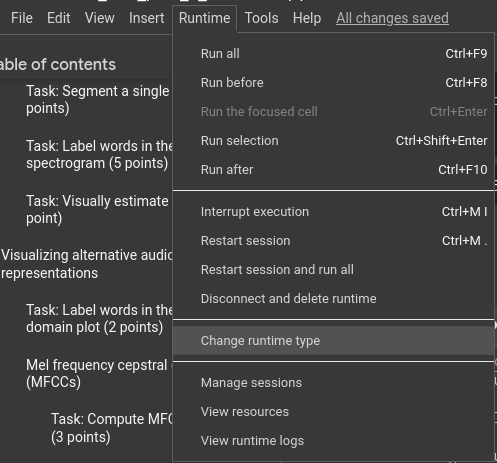

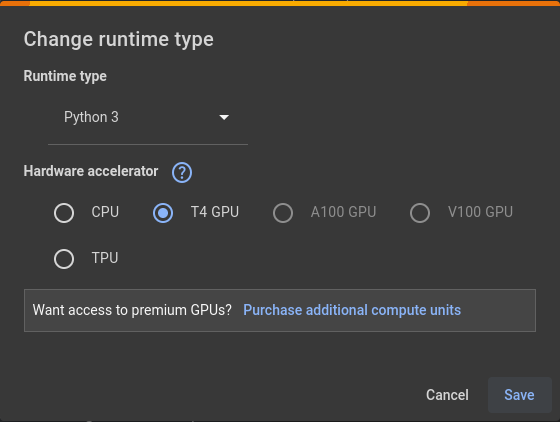

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
from transformers import AutoProcessor, BarkModel
processor = AutoProcessor.from_pretrained("suno/bark")
model = BarkModel.from_pretrained("suno/bark").to("cuda")
model.cuda()

voice_preset = "v2/en_speaker_6"


In [ ]:
# You can change the text if you want

your_text = 'Back in my day, I had to walk to school uphill... both ways'

inputs = processor(your_text, voice_preset=voice_preset).to("cuda")

bark_audio_array = model.generate(**inputs)
bark_audio_array = bark_audio_array.cpu().numpy().squeeze()
bark_sr = model.generation_config.sample_rate

# plot the audio
fig, ax = plt.subplots(2,1,figsize=(20,15))
plot_melspectrogram(bark_audio_array, bark_sr, fig=fig, ax=ax[0])
librosa.display.waveshow(bark_audio_array, sr=bark_sr, ax=ax[1])

Audio(data=bark_audio_array, rate=bark_sr)

### 6.4.2 Compare to normal TTS systems

In [ ]:
# Generate at least 1 sample for Bark. Visualize the utterance in a spectrogram

#############################
#### YOUR CODE GOES HERE ####

# Use the same sentence as one of your Rime.ai generations, for a fair comparison
bark_text_compare = "This is Harper Valley National Bank. My name is Elizabeth. How can I help you today?"

inputs_compare = processor(bark_text_compare, voice_preset=voice_preset).to("cuda")
bark_audio_compare = model.generate(**inputs_compare)
bark_audio_compare = bark_audio_compare.cpu().numpy().squeeze()

fig, ax = plt.subplots(2, 1, figsize=(20, 10))
plot_melspectrogram(bark_audio_compare, bark_sr, fig=fig, ax=ax[0])
librosa.display.waveshow(bark_audio_compare, sr=bark_sr, ax=ax[1])
plt.show()

ipd.Audio(data=bark_audio_compare, rate=bark_sr)

#############################

### 6.4.3 Generate audio that a normal TTS can't produce

In [ ]:
# Generate at least 1 sample for Bark. Visualize the utterance in a spectrogram
# Comment on applications where you might prefer Bark over traditional TTS

#############################
#### YOUR CODE GOES HERE ####

# Bark supports special tags for non-speech sounds and singing, something
# a normal TTS system can't produce
bark_text_special = "♪ Never gonna give you up, never gonna let you down ♪ [laughs] I really mean it!"

inputs_special = processor(bark_text_special, voice_preset=voice_preset).to("cuda")
bark_audio_special = model.generate(**inputs_special)
bark_audio_special = bark_audio_special.cpu().numpy().squeeze()

fig, ax = plt.subplots(2, 1, figsize=(20, 10))
plot_melspectrogram(bark_audio_special, bark_sr, fig=fig, ax=ax[0])
librosa.display.waveshow(bark_audio_special, sr=bark_sr, ax=ax[1])
plt.show()

ipd.Audio(data=bark_audio_special, rate=bark_sr)

#############################

# THE END